# Monitoreo no invasivo de adultos mayores con VLC asistida por IRS

**Objetivo.** Avisar a un cuidador cuando el movimiento de un adulto mayor que vive solo se aparta de su rutina habitual (caída, detención prolongada, deambulación, marcha lenta), **sin cámaras, sin dispositivos que deba llevar puestos y sin canal de subida IR o RF**. Solo se usan las luminarias VLC de la casa y un panel de espejos (IRS).

**Idea central.** Un mismo modelo CNN–GRU, entrenado con la rutina del ocupante, cumple dos funciones:

1. **Monitoreo (servicio principal):** el residuo entre la trayectoria que predijo y la que observa la infraestructura es el puntaje de anomalía que dispara la alerta.
2. **Comunicación (servicio de soporte):** la posición predicha orienta los espejos para sostener el enlace VLC cuando el cuerpo bloquea la línea de vista.

**Cambios respecto de la versión anterior del código**

| Antes | Ahora |
|---|---|
| Caminatas aleatorias | Rutina entre lugares habituales de la casa |
| Entrada: posición **y orientación del terminal** (requería telemetría de subida) | Entrada: solo posición (x, y) estimada por la sombra en los fotodiodos de la infraestructura |
| Salida: 2N ángulos a un paso | Salida: recorrido del próximo segundo; los ángulos salen de la ec. (2) del paper |
| Se evaluaba solo la tasa | Se evalúa la **alerta** (detección, falsas alarmas/h, retardo) y la tasa como requisito |

El modelo de canal (`ris_vlc.py`) **no cambia**.

In [1]:
import json, time
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt

import ris_vlc as rv
import sim_aal as sim
import modelo_aal as mdl
import evaluacion_aal as ev

torch.set_num_threads(2)
FIG = Path('figuras'); FIG.mkdir(exist_ok=True)

# Paleta validada (daltonismo y contraste)
C = dict(cnn_gru='#0092a8', cv='#7b5cc4', regla='#d4771f', reactivo='#d4771f',
         ideal='#9aa0a6', normal='#7d8590', caida='#c2427e', detencion='#d4771f',
         deambulacion='#7b5cc4', marcha_lenta='#0092a8')
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e6e6', 'grid.linewidth': 0.6,
                     'legend.frameon': False, 'figure.dpi': 110, 'savefig.bbox': 'tight'})

CFG = sim.CFG
esc = rv.Escenario()
SEMILLAS = dict(train=1000, val=2000, calibracion=3000, test_normal=4000, test_anomalia=5000)
N = dict(train=160, val=40, calibracion=40, test_normal=40, test_anomalia=40)
print(json.dumps({k: CFG[k] for k in ['dt', 'steps', 'history', 'horizon', 'pos_noise',
                                      'device_offset', 'slew_deg_s', 'r_min']}, indent=1))

{
 "dt": 0.1,
 "steps": 900,
 "history": 10,
 "horizon": 10,
 "pos_noise": 0.05,
 "device_offset": 0.2,
 "slew_deg_s": 120.0,
 "r_min": 5.0
}


## 1. Escenario y canal (sin cambios)

Sala de 5×5×3 m, LED en el centro del techo y panel de 100 espejos en la pared x = 0 (Tabla II del paper). El mapa muestra la tasa que entrega **solo el IRS** con los espejos perfectamente apuntados a un terminal a 0.85 m mirando hacia arriba. El panel cubre la mitad oeste de la pieza: fuera de esa zona, si el cuerpo bloquea la línea de vista, ningún apuntamiento recupera el enlace.

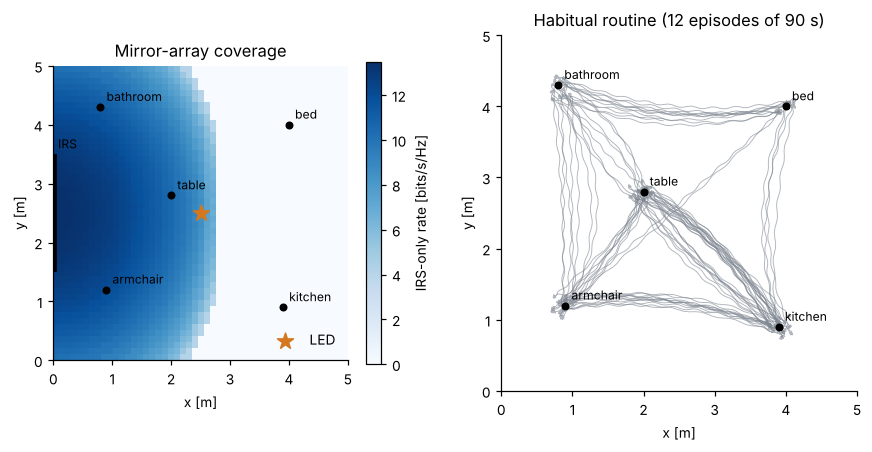

In [2]:
g = np.linspace(0.1, 4.9, 49)
mapa = np.zeros((len(g), len(g)))
up = np.array([0.0, 0.0, 1.0])
for i, x in enumerate(g):
    for j, y in enumerate(g):
        p = np.array([x, y, CFG['device_height']])
        mapa[j, i] = rv.tasa(esc, rv.ganancia_irs(esc, p, up, rv.normales_optimas(esc, p)))

ejemplos = sim.generar(SEMILLAS['train'], 12)
fig, ax = plt.subplots(1, 2, figsize=(9.5, 4.2))
im = ax[0].imshow(mapa, origin='lower', extent=[0, 5, 0, 5], cmap='Blues', vmin=0)
fig.colorbar(im, ax=ax[0], label='IRS-only rate [bits/s/Hz]', shrink=0.85)
ax[0].plot([0, 0], [1.5, 3.5], color='k', lw=5, solid_capstyle='butt')
ax[0].text(0.08, 3.6, 'IRS', fontsize=8)
ax[0].scatter(2.5, 2.5, marker='*', s=120, color='#d4771f', zorder=3, label='LED')
for e in ejemplos:
    ax[1].plot(*e['body'].T, color=C['normal'], lw=0.6, alpha=0.6)
for k, n in enumerate(sim.NOMBRES):
    for a in ax:
        a.scatter(*sim.POI[k], color='k', s=18, zorder=4)
        a.annotate(sim.LUGARES_EN[n], sim.POI[k], textcoords='offset points', xytext=(4, 4), fontsize=8)
ax[0].legend(loc='lower right'); ax[0].set_title('Mirror-array coverage')
ax[1].set_title('Habitual routine (12 episodes of 90 s)')
for a in ax:
    a.set_xlim(0, 5); a.set_ylim(0, 5); a.set_aspect('equal'); a.grid(False)
    a.set_xlabel('x [m]'); a.set_ylabel('y [m]')
fig.savefig(FIG / 'escenario_rutina.pdf'); plt.show()

## 2. Rutina, sensado no invasivo y eventos anómalos

**Rutina.** El ocupante va entre cinco lugares (cama, baño, sillón, mesa, cocina) según una matriz de transición fija, por rutas habituales (curvas con desvío propio de cada par de lugares), a una velocidad habitual de 0.55–0.75 m/s con aceleración y frenado suaves, y se queda 4–14 s en cada lugar con micromovimientos.

**Sensado.** La infraestructura solo obtiene la posición (x, y) del cuerpo, con error gaussiano de 5 cm por coordenada, a partir de la sombra que el cuerpo produce en los fotodiodos de la luminaria y del panel. **No se usa la orientación del terminal, ni su altura, ni ningún canal de subida.** El mecanismo de estimación se modela como ruido; no se simula en detalle.

**Terminal VLC.** Cuando el ocupante usa un teléfono o tablet, se asume sostenido 20 cm delante del cuerpo a 0.85 m. El propio cuerpo (cilindro de 0.15 m de radio y 1.6 m de alto) puede bloquear la línea de vista, que es el caso que motiva el IRS.

**Eventos anómalos** (uno por episodio, entre 20 y 60 s, a mitad de un trayecto):

- **Caída:** el cuerpo se desplaza 0.5–0.8 m en 0.8 s y queda inmóvil; el terminal cae a 0.2 m y se inclina 60–90°.
- **Detención prolongada:** frena a mitad de camino y queda de pie inmóvil.
- **Deambulación:** abandona la ruta y camina sin destino con giros frecuentes.
- **Marcha lenta:** sigue la ruta habitual al 40–55 % de su velocidad.

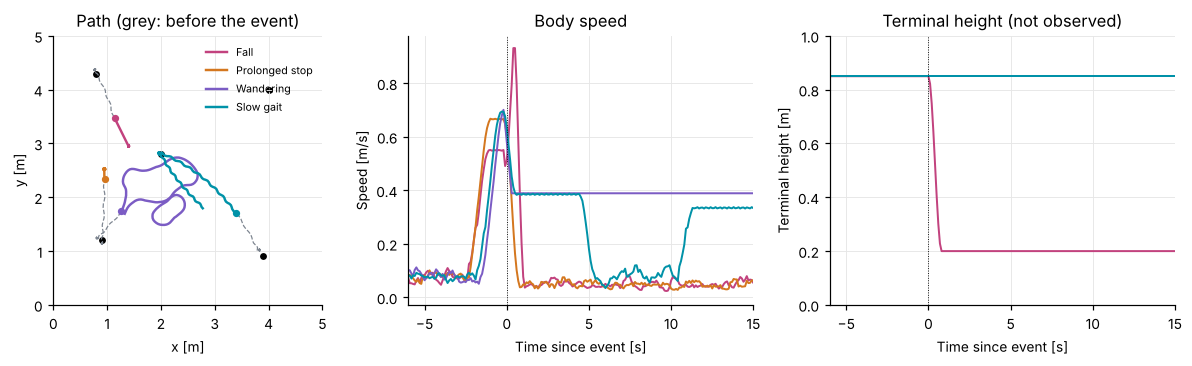

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.4), gridspec_kw=dict(width_ratios=[1, 1.2, 1.2]))
for i, a in enumerate(sim.ANOMALIAS):
    e = sim.generar(SEMILLAS['test_anomalia'] + i, 1, a)[0]
    te, t = e['t_ev'], np.arange(CFG['steps']) * CFG['dt'] - e['t_ev'] * CFG['dt']
    ax[0].plot(*e['body'][max(te - 60, 0):te + 1].T, color=C['normal'], lw=0.8, ls='--')
    ax[0].plot(*e['body'][te:te + 150].T, color=C[a], lw=1.6, label=sim.ETIQUETAS[a])
    ax[0].scatter(*e['body'][te], color=C[a], s=14, zorder=3)
    v = np.r_[np.nan, np.linalg.norm(np.diff(e['body'], axis=0), axis=1) / CFG['dt']]
    vs = np.convolve(np.nan_to_num(v), np.ones(5) / 5, mode='same')
    ax[1].plot(t, vs, color=C[a], lw=1.3)
    ax[2].plot(t, e['dev'][:, 2], color=C[a], lw=1.3)
ax[0].scatter(*sim.POI.T, color='k', s=12)
ax[0].set(xlim=(0, 5), ylim=(0, 5), aspect='equal', xlabel='x [m]', ylabel='y [m]',
          title='Path (grey: before the event)')
ax[0].legend(fontsize=7, loc='upper right')
ax[1].set(xlim=(-6, 15), xlabel='Time since event [s]', ylabel='Speed [m/s]',
          title='Body speed')
ax[2].set(xlim=(-6, 15), ylim=(0, 1), xlabel='Time since event [s]',
          ylabel='Terminal height [m]', title='Terminal height (not observed)')
for a in ax[1:]:
    a.axvline(0, color='k', lw=0.6, ls=':')
fig.tight_layout(); fig.savefig(FIG / 'eventos_anomalos.pdf'); plt.show()

## 3. Modelo CNN–GRU

Cada instante, la infraestructura arma 10 mapas cenitales de 20×20 (el último segundo) con dos canales: la posición observada del ocupante y los lugares habituales de la casa. Dos bloques convolucionales extraen rasgos de cada mapa; una GRU de 64 unidades los combina con la posición y la velocidad observadas, y una capa lineal entrega el **desplazamiento de los próximos 10 pasos (1 s)**. Se entrena solo con trayectorias **normales**: el modelo aprende la rutina, no las anomalías.

Si `cnn_gru_aal.pt` existe se cargan los pesos (12 épocas, ~8 min en CPU de 2 núcleos); si no, se entrena.

Parámetros: 60492 | ventanas de entrenamiento: 35360


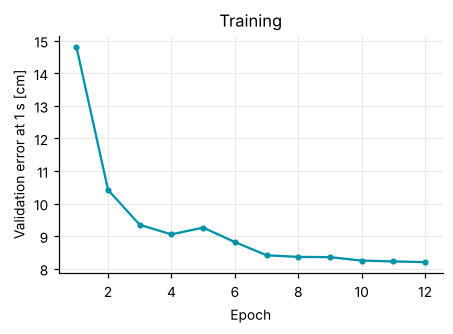

In [4]:
tr = sim.generar(SEMILLAS['train'], N['train'])
va = sim.generar(SEMILLAS['val'], N['val'])
Xtr, Ytr = mdl.ventanas(tr, stride=4)
Xva, Yva = mdl.ventanas(va, stride=5)
modelo = mdl.CNNGRU()
print('Parámetros:', sum(p.numel() for p in modelo.parameters()), '| ventanas de entrenamiento:', len(Xtr))

PESOS = Path('cnn_gru_aal.pt')
if PESOS.exists():
    modelo.load_state_dict(torch.load(PESOS))
    hist = json.load(open('entrenamiento.json'))['hist']
else:
    t0 = time.time()
    hist = mdl.entrenar(modelo, Xtr, Ytr, Xva, Yva, epocas=12, seed=0)
    torch.save(modelo.state_dict(), PESOS)
    json.dump(dict(hist=hist, segundos=time.time() - t0, n_train=len(Xtr)), open('entrenamiento.json', 'w'))
modelo.eval()

fig, ax = plt.subplots(figsize=(4.5, 2.8))
ax.plot(np.arange(1, len(hist) + 1), [100 * h[1] for h in hist], color=C['cnn_gru'], marker='o', ms=3)
ax.set(xlabel='Epoch', ylabel='Validation error at 1 s [cm]', title='Training')
plt.show()

## 4. Puntaje de anomalía

En cada instante *t* se compara la posición observada con las 10 predicciones que el modelo hizo para ese instante desde *t*−1, …, *t*−10. El **residuo** es la distancia media, y el **puntaje** es su media móvil de 1 s. Mientras el ocupante sigue su rutina el residuo es pequeño; cuando hace algo que la rutina no explica, el residuo crece.

Se comparan tres detectores, todos con la misma observación:

- **Residuo CNN–GRU** (propuesto).
- **Residuo de velocidad constante:** mismo puntaje, pero con una extrapolación geométrica que no conoce la rutina.
- **Regla de inmovilidad:** alerta si el ocupante lleva ≥ 3 s inmóvil lejos de un lugar habitual. No aprende nada, pero conoce el plano de la casa.

**Calibración.** El umbral de cada residuo es el máximo puntaje observado en una hora de historial normal del propio ocupante (40 episodios). El umbral de la regla (3 s) se fija a priori. Una vez disparada, la alerta queda activa hasta que el cuidador la atiende (período refractario de 30 s para contar falsas alarmas).

In [5]:
t0 = time.time()
cal = sim.generar(SEMILLAS['calibracion'], N['calibracion'])
norm = sim.generar(SEMILLAS['test_normal'], N['test_normal'])
anom = {a: sim.generar(SEMILLAS['test_anomalia'] + i, N['test_anomalia'], a)
        for i, a in enumerate(sim.ANOMALIAS)}
sc_cal = [ev.puntajes(e, modelo) for e in cal]
sc_norm = [ev.puntajes(e, modelo) for e in norm]
sc_an = {a: [ev.puntajes(e, modelo) for e in anom[a]] for a in anom}
print(f'Puntajes calculados en {time.time() - t0:.0f} s')

# Error de predicción a 1 s sobre la trayectoria verdadera (test normal)
H = CFG['horizon']
for clave, nombre in [('pm', 'CNN–GRU'), ('pc', 'Velocidad constante')]:
    err = np.concatenate([np.linalg.norm(s[clave][:-H, -1] - e['body'][H:], axis=1)
                          for e, s in zip(norm, sc_norm)])
    print(f'Error de predicción a 1 s, {nombre}: {100 * np.nanmean(err):.1f} cm')

Puntajes calculados en 180 s
Error de predicción a 1 s, CNN–GRU: 8.4 cm
Error de predicción a 1 s, Velocidad constante: 19.9 cm


In [6]:
TAU = {'cnn_gru': ev.umbral_calibrado(cal, sc_cal, 'cnn_gru'),
       'cv': ev.umbral_calibrado(cal, sc_cal, 'cv'),
       'regla': 3.0}
todos_eps = norm + sum(anom.values(), [])
todos_sc = sc_norm + sum(sc_an.values(), [])

filas, resumen = [], {}
for met in ev.METODOS:
    fa = ev.falsas_por_hora(todos_eps, todos_sc, met, TAU[met])
    resumen[met] = dict(umbral=TAU[met], falsas_por_hora=fa)
    fila = [ev.NOMBRE_METODO[met], f'{fa:.1f}']
    for a in sim.ANOMALIAS:
        d, r = ev.deteccion(anom[a], sc_an[a], met, TAU[met])
        med = float(np.median(r)) if r else None
        resumen[met][a] = dict(deteccion=d, retardo_mediano_s=med)
        fila.append(f'{100 * d:.0f} % ({med:.1f} s)' if r else '0 %')
    filas.append(fila)

horas = sum((e['t_ev'] or len(e['obs'])) for e in todos_eps) * CFG['dt'] / 3600
print(f'Falsas alarmas contadas sobre {horas:.2f} h de movimiento normal.\n')
enc = ['Detector', 'Falsas/h'] + [sim.ETIQUETAS[a] for a in sim.ANOMALIAS]
ancho = [28, 9] + [22] * 4
print(''.join(h.ljust(w) for h, w in zip(enc, ancho)))
for f in filas:
    print(''.join(str(c).ljust(w) for c, w in zip(f, ancho)))
print('\nDetección dentro de 10 s desde el evento; entre paréntesis, retardo mediano.')

Falsas alarmas contadas sobre 3.02 h de movimiento normal.

Detector                    Falsas/h Fall                  Prolonged stop        Wandering             Slow gait             
CNN–GRU residual            2.0      92 % (1.8 s)          78 % (1.5 s)          85 % (2.8 s)          0 %                   
Constant-velocity residual  0.0      70 % (1.6 s)          0 %                   40 % (4.2 s)          0 %                   
Immobility rule             0.0      90 % (4.8 s)          100 % (4.3 s)         0 %                   0 %                   

Detección dentro de 10 s desde el evento; entre paréntesis, retardo mediano.


### Compromiso detección / falsas alarmas

La tabla depende del umbral elegido. Barriendo el umbral se obtiene, para cada detector, la tasa de detección en función de las falsas alarmas por hora; el punto marca el umbral calibrado.

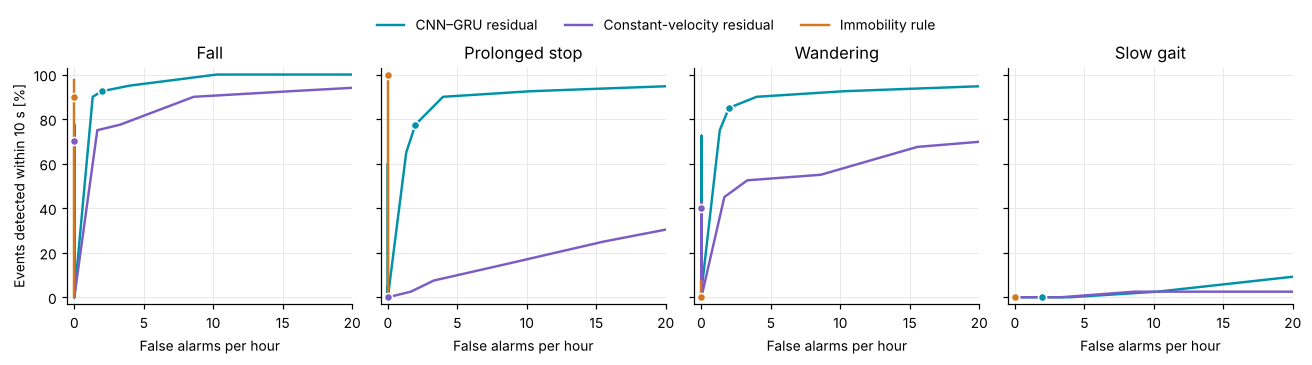

Detección a ≤ 2.0 falsas alarmas/h:
  CNN–GRU residual            Fall: 92 %  Prolonged stop: 78 %  Wandering: 85 %  Slow gait: 0 %
  Constant-velocity residual  Fall: 75 %  Prolonged stop: 2 %  Wandering: 45 %  Slow gait: 0 %
  Immobility rule             Fall: 98 %  Prolonged stop: 100 %  Wandering: 8 %  Slow gait: 0 %


In [7]:
def curva(met, a, taus):
    fa = [ev.falsas_por_hora(todos_eps, todos_sc, met, t) for t in taus]
    det = [ev.deteccion(anom[a], sc_an[a], met, t)[0] for t in taus]
    return np.array(fa), 100 * np.array(det)

barridos = {'cnn_gru': np.linspace(0.12, 0.45, 34), 'cv': np.linspace(0.12, 0.45, 34),
            'regla': np.arange(0.5, 10.01, 0.5)}
fig, ax = plt.subplots(1, 4, figsize=(12, 3.1), sharey=True)
curvas = {}
for k, a in enumerate(sim.ANOMALIAS):
    for met in ev.METODOS:
        fa, det = curva(met, a, barridos[met])
        curvas[(met, a)] = (fa, det)
        orden = np.argsort(fa)
        ax[k].plot(fa[orden], det[orden], color=C[met], lw=1.6,
                   label=ev.NOMBRE_METODO[met] if k == 0 else None)
        fa0, det0 = curva(met, a, [TAU[met]])
        ax[k].scatter(fa0, det0, color=C[met], s=28, zorder=3, edgecolor='white', lw=1)
    ax[k].set(title=sim.ETIQUETAS[a], xlabel='False alarms per hour', xlim=(-0.5, 20), ylim=(-3, 103))
ax[0].set_ylabel('Events detected within 10 s [%]')
fig.legend(loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.07))
fig.tight_layout(); fig.savefig(FIG / 'deteccion_vs_falsas.pdf'); plt.show()

# Comparación a igual tasa de falsas alarmas que el residuo CNN–GRU calibrado
fa_ref = resumen['cnn_gru']['falsas_por_hora']
igual_fa = {}
for met in ['cv', 'regla']:
    igual_fa[met] = {}
    for a in sim.ANOMALIAS:
        fa, det = curvas[(met, a)]
        igual_fa[met][a] = float(det[fa <= fa_ref + 1e-9].max() / 100) if (fa <= fa_ref + 1e-9).any() else 0.0
print(f'Detección a ≤ {fa_ref:.1f} falsas alarmas/h:')
for met in ['cnn_gru', 'cv', 'regla']:
    vals = [resumen['cnn_gru'][a]['deteccion'] if met == 'cnn_gru' else igual_fa[met][a] for a in sim.ANOMALIAS]
    print(f'  {ev.NOMBRE_METODO[met]:28s}' + '  '.join(f'{sim.ETIQUETAS[a]}: {100 * v:.0f} %' for a, v in zip(sim.ANOMALIAS, vals)))

### Cómo se ve el puntaje en el tiempo

Un episodio por tipo de evento. La línea horizontal es el umbral calibrado de cada residuo. En los episodios normales el puntaje sube cuando el ocupante sale de un lugar habitual (el momento exacto de partida no es predecible), y eso es lo que fija el umbral.

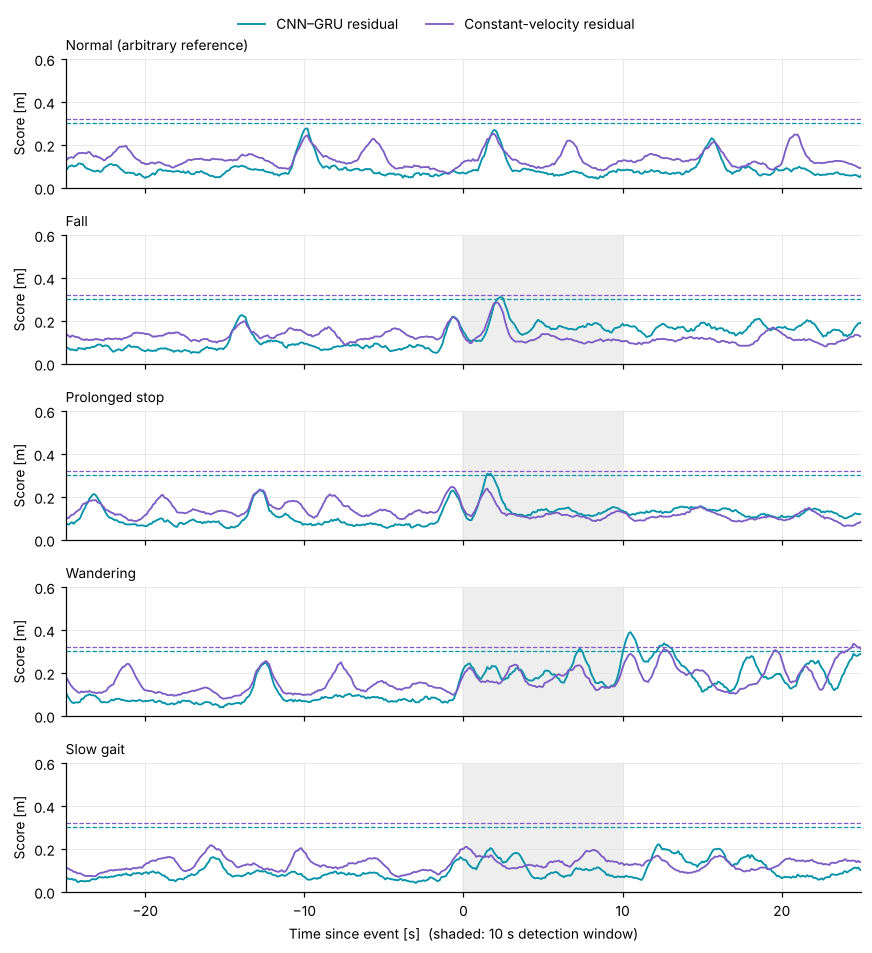

In [8]:
casos = [('normal', norm[0], sc_norm[0])] + [(a, anom[a][0], sc_an[a][0]) for a in sim.ANOMALIAS]
fig, ax = plt.subplots(len(casos), 1, figsize=(8, 8.5), sharex=True)
for k, (tipo, e, s) in enumerate(casos):
    ref = e['t_ev'] if e['t_ev'] is not None else 300
    t = (np.arange(CFG['steps']) - ref) * CFG['dt']
    for met in ['cnn_gru', 'cv']:
        ax[k].plot(t, s[met], color=C[met], lw=1.2, label=ev.NOMBRE_METODO[met] if k == 0 else None)
        ax[k].axhline(TAU[met], color=C[met], lw=0.8, ls='--')
    if e['t_ev'] is not None:
        ax[k].axvspan(0, 10, color='#eeeeee', zorder=0)
    ax[k].set_ylabel('Score [m]')
    ax[k].set_title(sim.ETIQUETAS[tipo] + ('' if e['t_ev'] is not None else ' (arbitrary reference)'),
                    loc='left', fontsize=9)
    ax[k].set_ylim(0, 0.6)
ax[-1].set_xlabel('Time since event [s]  (shaded: 10 s detection window)')
ax[-1].set_xlim(-25, 25)
fig.legend(loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.02))
fig.tight_layout(); fig.savefig(FIG / 'puntaje_en_el_tiempo.pdf'); plt.show()

## 5. Capa de comunicación como requisito del servicio

Cuatro estrategias apuntan los espejos cada 100 ms. Todas usan solo la posición (x, y) estimada y asumen el terminal a 0.85 m, 20 cm delante del cuerpo en la dirección de avance estimada, porque **sin canal de subida no se conoce ni la altura ni la orientación del terminal**. La actuación está limitada a 120°/s y ±80°. El canal se evalúa con la posición, la orientación y el bloqueo verdaderos.

- **Ideal:** apunta instantáneamente a la posición verdadera del terminal (cota superior).
- **Reactiva:** apunta a la última observación.
- **Velocidad constante:** apunta a la posición extrapolada.
- **CNN–GRU:** apunta a la posición predicha para el siguiente intervalo.

En los episodios normales se promedia todo el episodio; en los anómalos, solo desde el evento.

In [9]:
t0 = time.time()
CTRL = ['ideal', 'reactivo', 'cv', 'cnn_gru']
NOMBRE_CTRL = {'ideal': 'Ideal', 'reactivo': 'Reactive', 'cv': 'Constant velocity', 'cnn_gru': 'CNN–GRU'}
inicio = CFG['history'] + CFG['horizon']

def enlace(eps, scs, desde_evento):
    acc = {c: [] for c in CTRL}
    for e, s in zip(eps, scs):
        r = ev.evaluar_enlace(esc, e, s)
        k = e['t_ev'] - inicio if desde_evento else 0
        for c in CTRL:
            acc[c].append(r[c][k:])
    return {c: dict(tasa=float(np.concatenate(v).mean()),
                    indisponibilidad=float(100 * (np.concatenate(v) < CFG['r_min']).mean())) for c, v in acc.items()}

res_enlace = {'normal': enlace(norm, sc_norm, False)}
for a in sim.ANOMALIAS:
    res_enlace[a] = enlace(anom[a], sc_an[a], True)
print(f'Enlace evaluado en {time.time() - t0:.0f} s\n')
print('Escenario'.ljust(22) + ''.join(NOMBRE_CTRL[c].ljust(22) for c in CTRL))
for esc_k, v in res_enlace.items():
    print(sim.ETIQUETAS[esc_k].ljust(22) +
          ''.join(f"{v[c]['tasa']:.2f} / {v[c]['indisponibilidad']:.0f} %".ljust(22) for c in CTRL))
print('\nTasa media [bits/s/Hz] / indisponibilidad (tasa < 5 bits/s/Hz)')

Enlace evaluado en 171 s

Escenario             Ideal                 Reactive              Constant velocity     CNN–GRU               
Normal                8.83 / 20 %           7.51 / 25 %           7.72 / 24 %           7.95 / 24 %           
Fall                  6.41 / 42 %           1.08 / 88 %           1.08 / 88 %           1.08 / 88 %           
Prolonged stop        10.28 / 7 %           9.46 / 8 %            9.53 / 8 %            8.79 / 10 %           
Wandering             9.07 / 13 %           7.79 / 19 %           7.77 / 19 %           7.60 / 21 %           
Slow gait             8.62 / 22 %           7.58 / 26 %           7.72 / 25 %           7.73 / 25 %           

Tasa media [bits/s/Hz] / indisponibilidad (tasa < 5 bits/s/Hz)


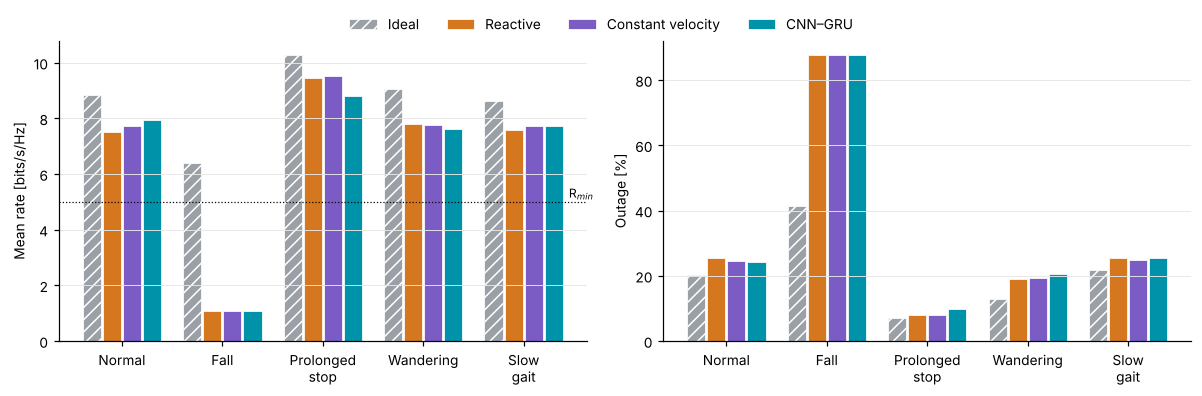

In [10]:
esc_orden = ['normal'] + sim.ANOMALIAS
x = np.arange(len(esc_orden)); w = 0.2
color_ctrl = dict(ideal=C['ideal'], reactivo=C['reactivo'], cv=C['cv'], cnn_gru=C['cnn_gru'])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for j, c in enumerate(CTRL):
    for k, met in enumerate(['tasa', 'indisponibilidad']):
        ax[k].bar(x + (j - 1.5) * w, [res_enlace[s][c][met] for s in esc_orden], w * 0.9,
                  color=color_ctrl[c], label=NOMBRE_CTRL[c] if k == 0 else None,
                  hatch='///' if c == 'ideal' else None, edgecolor='white', lw=0.5)
ax[0].axhline(CFG['r_min'], color='k', lw=0.8, ls=':'); ax[0].text(4.45, 5.15, 'R$_{min}$', fontsize=8)
ax[0].set_ylabel('Mean rate [bits/s/Hz]'); ax[1].set_ylabel('Outage [%]')
for a in ax:
    a.set_xticks(x, [sim.ETIQUETAS[s].replace(' ', '\n', 1) for s in esc_orden]); a.grid(axis='x', visible=False)
fig.legend(loc='upper center', ncol=4, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout(); fig.savefig(FIG / 'enlace_por_escenario.pdf'); plt.show()

## 6. Resumen para el informe

In [11]:
resultados = dict(
    parametros_modelo=int(sum(p.numel() for p in modelo.parameters())),
    error_prediccion_1s_cm={k: float(100 * np.nanmean(np.concatenate(
        [np.linalg.norm(s[c][:-H, -1] - e['body'][H:], axis=1) for e, s in zip(norm, sc_norm)])))
        for k, c in [('cnn_gru', 'pm'), ('velocidad_constante', 'pc')]},
    horas_normales_evaluadas=horas,
    alerta=resumen,
    deteccion_a_igual_falsas_por_hora=igual_fa,
    enlace=res_enlace,
)
json.dump(resultados, open('resultados_aal.json', 'w'), indent=1, ensure_ascii=False)
print(json.dumps(resultados, indent=1, ensure_ascii=False))

{
 "parametros_modelo": 60492,
 "error_prediccion_1s_cm": {
  "cnn_gru": 8.38315801237077,
  "velocidad_constante": 19.880378361724762
 },
 "horas_normales_evaluadas": 3.024611111111111,
 "alerta": {
  "cnn_gru": {
   "umbral": 0.3005290795937827,
   "falsas_por_hora": 1.9837260988556829,
   "caida": {
    "deteccion": 0.925,
    "retardo_mediano_s": 1.8
   },
   "detencion": {
    "deteccion": 0.775,
    "retardo_mediano_s": 1.5
   },
   "deambulacion": {
    "deteccion": 0.85,
    "retardo_mediano_s": 2.8000000000000003
   },
   "marcha_lenta": {
    "deteccion": 0.0,
    "retardo_mediano_s": null
   }
  },
  "cv": {
   "umbral": 0.321512733365071,
   "falsas_por_hora": 0.0,
   "caida": {
    "deteccion": 0.7,
    "retardo_mediano_s": 1.6
   },
   "detencion": {
    "deteccion": 0.0,
    "retardo_mediano_s": null
   },
   "deambulacion": {
    "deteccion": 0.4,
    "retardo_mediano_s": 4.2
   },
   "marcha_lenta": {
    "deteccion": 0.0,
    "retardo_mediano_s": null
   }
  },
  "reg

## 7. Alcance y limitaciones

- **Simulación.** Rutina, anomalías y sensado son sintéticos. La caída es una perturbación cinemática simplificada, no un modelo biomecánico, y el estimador de posición por sombra se modela como ruido gaussiano de 5 cm, sin simularlo.
- **Un solo ocupante y una sola rutina.** El umbral se calibra con una hora de historial; en una casa real la rutina cambia según la hora del día y el día de la semana.
- **Marcha lenta.** Es un cambio sostenido y sutil. Un puntaje con ventana de 1 s no lo distingue de la variabilidad normal; requiere estadísticas de largo plazo (por ejemplo, la velocidad media de cada trayecto a lo largo de días).
- **Enlace tras una caída.** Sin canal de subida no se conoce la altura del terminal, por lo que ninguna estrategia sostiene el enlace hacia un teléfono en el suelo. La alerta no depende de ese enlace, porque usa solo sensado de infraestructura.
- **Canal.** Se mantienen los supuestos de `ris_vlc.py`: reflexión especular de primer orden, sin sombra mutua entre espejos y sin bloqueo del tramo reflejado; las tasas son una cota optimista.
- **Una sola semilla de entrenamiento.** Antes de afirmar diferencias pequeñas entre métodos conviene repetir con varias semillas.